In [44]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import RelaxationTissueModel

microtorch_model = ModelMaker("SphereBallAstrosticks")
sphere, ball, astrosticks = microtorch_model.compartments

# Sphere's diffusivity is fixed inside the compartment, not a model parameter.
sphere.fixed_D = 2

# Make Astrosticks use a fixed D_par of 8.0.
astrosticks.fixed_D_par = 2.0
astrosticks.parameter_ranges = [[2.0, 2.0]]
microtorch_model.parameter_ranges[-1, :] = [2.0, 2.0]

model = MicrotorchTissueModel(
    microtorch_model,
    parameters={
        "radius": 6.0,  # Sphere radius
        "D": 2,        # Ball diffusivity
        "D_par": 2.0,    # Astrosticks parallel diffusivity
        "f_0": 0.6,      # Sphere
        "f_1": 0.3,      # Ball
        "f_2": 0.1,      # Astrosticks; derived from f_0 and f_1
    },
)

# Keep the Ball and Astrosticks diffusivities fixed during fitting.
for name in ("D", "D_par"):
    model[name].optimize = False
    model[name].fit_flag = False



model["radius"].value_list = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14,15]

model = RelaxationTissueModel(model=model, t2=0.05)



model["T2"].optimize = True
model["T2"].fit_flag = True
print("Sphere fixed diffusivity:", sphere.fixed_D)
print(model)

No YAML configuration found for SphereBallAstrosticks model.
Falling back to parsing model name for compartments: ['Sphere', 'Ball', 'Astrosticks'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  SphereBallAstrosticks
########### Compartments: ['Sphere', 'Ball', 'Astrosticks']
########### Parameter names: [['radius'], ['D'], ['D_par']]
########### Parameter ranges: [[[0.001, 15]], [[0.001, 3]], [[0.5, 3.0]]]
-----------
Sphere fixed diffusivity: 2
Tissue model with 8 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_radius           6       1      True        True   (0.001, 15.0)
model_D                2       1      False       False  (0.001, 3.0)
model_D_par            2       1      False       False  (2.0, 2.0)
model_f_0              0.6     1      True        True   (0.0, 1.0)
model_f_1              0.3     1      True  

In [45]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 5
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28]
Gradient-magnitude free indices: [ 1  8 15 22 29]
b0 gradient magnitudes: [-0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False]
Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                  

In [46]:
from copy import deepcopy
import numpy as np

scheme = deepcopy(initial_scheme)
x0 = scheme.scaled_free_parameter_vector.copy()

for name, constraint in scheme.constraints.items():
    scheme.set_scaled_free_parameter_vector(x0)
    values = np.atleast_1d(constraint.fun(x0))
    print(
        name,
        "values:", values.shape,
        "lower bounds:", np.shape(constraint.lb),
        "upper bounds:", np.shape(constraint.ub),
    )

scheme.set_scaled_free_parameter_vector(x0)

PulseIntervalLargerThanPulseDuration values: (35,) lower bounds: () upper bounds: ()
PulseMagnitudeSmallerThanMaxMagnitude values: (35,) lower bounds: () upper bounds: ()
EchoTimeLargerThanMinEchoTime values: (35,) lower bounds: () upper bounds: ()
BValueWithinBounds values: (30,) lower bounds: () upper bounds: ()


In [47]:
signal = model(initial_scheme)
print(signal)

[0.16529889 0.08992726 0.08992726 0.08992726 0.08992726 0.08992726
 0.08992726 0.26184567 0.13852317 0.13852317 0.13852317 0.13852317
 0.13852317 0.13852317 0.16529889 0.10189666 0.10189666 0.10189666
 0.10189666 0.10189666 0.10189666 0.27253179 0.20438099 0.20438099
 0.20438099 0.20438099 0.20438099 0.20438099 0.36787944 0.34436204
 0.34436204 0.34436204 0.34436204 0.34436204 0.34436204]


In [48]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)
print(jacobian.shape)

[[ 0.          0.          0.          0.00595076]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [-0.00844033  0.07992628 -0.05937277  0.00323738]
 [ 0.          0.          0.          0.00701746]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [-0.01517503  0.09374199 -0.11068873  0.00371242]
 [ 0.          0.          0.          0.00595076]
 [-0.00463791  0.06845088 -0.07513768  0.00366828]
 [-0.00463791  0.06845088 -0.07513768  0.00366828]
 [-0.00463791  0.06845088 -0.07513768  0.00366828]
 [-0.00463791  0.06845088 -0.07513768  0.00366828]
 [-0.00463791  0.06845088 -0.07

In [49]:
from microtool.optimize import optimize_scheme

optimal_scheme, _ = optimize_scheme(initial_scheme, model, noise_variance=0.05, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 1000,
    #"finite_diff_rel_step": 1e-8,  # Prevents large jumps during gradient estimation
    #"initial_tr_radius": 0.05        # Prevents trust radius from jumping to 35.0
})

| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |  21   |   0   | +4.2500e+02 | 1.00e+00 | 2.72e+01 | 0.00e+00 |


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


|   2   |  42   |   1   | +3.7291e+02 | 2.00e+00 | 1.81e+03 | 9.96e-03 |
|   3   |  63   |  16   | +3.4117e+02 | 1.20e+01 | 7.74e+02 | 0.00e+00 |
|   4   |  84   |  31   | +3.3545e+02 | 1.41e+01 | 6.90e+02 | 0.00e+00 |
|   5   |  105  |  47   | +3.3962e+02 | 1.41e+01 | 1.29e+02 | 0.00e+00 |
|   6   |  126  |  67   | +3.1374e+02 | 1.41e+01 | 1.41e+02 | 0.00e+00 |
|   7   |  168  |  87   | +3.1374e+02 | 1.41e+00 | 1.41e+02 | 0.00e+00 |
|   8   |  189  |  107  | +3.0652e+02 | 4.30e+00 | 7.03e+01 | 0.00e+00 |
|   9   |  210  |  127  | +2.9852e+02 | 4.30e+00 | 2.22e+01 | 0.00e+00 |
|  10   |  252  |  144  | +2.9830e+02 | 4.30e+00 | 4.27e+02 | 0.00e+00 |
|  11   |  273  |  164  | +2.9060e+02 | 4.52e+00 | 1.41e+01 | 0.00e+00 |
|  12   |  315  |  184  | +2.8506e+02 | 4.52e+00 | 1.23e+02 | 0.00e+00 |
|  13   |  357  |  204  | +2.7886e+02 | 4.52e+00 | 3.08e+02 | 0.00e+00 |
|  14   |  399  |  224  | +2.7886e+02 | 9.64e-01 | 3.08e+02 | 0.00e+00 |
|  15   |  441  |  243  | +2.7886e+02 | 4.82e-01 | 

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


|  52   | 1743  |  476  | +2.7804e+02 | 1.46e-09 | 1.29e+01 | 0.00e+00 |
|  53   | 1764  |  476  | +2.7804e+02 | 1.00e+00 | 1.30e+01 | 0.00e+00 |
|  54   | 1806  |  496  | +2.7804e+02 | 1.00e-01 | 1.30e+01 | 0.00e+00 |
|  55   | 1848  |  516  | +2.7804e+02 | 1.00e-02 | 1.30e+01 | 0.00e+00 |
|  56   | 1869  |  531  | +2.7799e+02 | 2.00e-02 | 1.70e+02 | 0.00e+00 |
|  57   | 1890  |  546  | +2.7751e+02 | 4.00e-02 | 4.16e+02 | 0.00e+00 |
|  58   | 1911  |  566  | +2.7617e+02 | 8.00e-02 | 1.07e+03 | 0.00e+00 |
|  59   | 1932  |  574  | +2.7370e+02 | 8.00e-02 | 2.62e+02 | 0.00e+00 |
|  60   | 1953  |  594  | +2.7352e+02 | 8.00e-02 | 5.90e+02 | 0.00e+00 |
|  61   | 1995  |  614  | +2.7352e+02 | 2.44e-02 | 5.90e+02 | 0.00e+00 |
|  62   | 2037  |  619  | +2.7352e+02 | 1.22e-02 | 5.90e+02 | 0.00e+00 |
|  63   | 2079  |  624  | +2.7352e+02 | 6.10e-03 | 5.90e+02 | 0.00e+00 |
|  64   | 2121  |  626  | +2.7352e+02 | 3.05e-03 | 5.90e+02 | 0.00e+00 |
|  65   | 2142  |  630  | +2.7338e+02 | 6.10e-03 | 

In [50]:
import numpy as np
import pandas as pd


def get_unique_shells(scheme, scheme_name="Scheme"):
    df = pd.DataFrame(
        {
            "Scheme": scheme_name,
            "b_value": np.round(scheme.b_values, 1),
            "TE_ms": np.round(scheme.echo_times * 1e3, 2),
            "delta_ms": np.round(scheme.pulse_durations * 1e3, 2),
            "Delta_ms": np.round(scheme.pulse_intervals * 1e3, 2),
        }
    )

    # Filter out b = 0
    df_nonzero = df[df["b_value"] > 0]

    # Group by unique parameters and count directions
    shells = (
        df_nonzero.groupby(
            ["Scheme", "b_value", "TE_ms", "delta_ms", "Delta_ms"], as_index=False
        )
        .size()
        .rename(columns={"size": "N_directions"})
    )
    return shells


# Combine initial and optimal shells
shells_initial = get_unique_shells(initial_scheme, scheme_name="Initial")
shells_optimal = get_unique_shells(optimal_scheme, scheme_name="Optimal")

combined_shells = pd.concat([shells_initial, shells_optimal], ignore_index=True)

print(combined_shells.to_string(index=False))

 Scheme  b_value  TE_ms  delta_ms  Delta_ms  N_directions
Initial     90.0  50.00     12.20     23.80             6
Initial    500.0  65.00     12.20     31.30             6
Initial   1500.0  90.00     24.70     43.40             6
Initial   2000.0  67.00     13.20     32.30             6
Initial   2999.0  90.00     24.70     43.80             6
Optimal      3.3  55.98     17.37     31.12             6
Optimal    501.1  49.13     14.71     25.81             6
Optimal   1300.6  76.75     26.08     43.18             6
Optimal   1449.3  80.67     23.91     49.32             6
Optimal   2173.4  46.85     15.40     26.19             6


In [53]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

model["model_radius"].value =12
print(model)


# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result

Tissue model with 8 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_radius          12       1      True        True   (0.001, 15.0)
model_D                2       1      False       False  (0.001, 3.0)
model_D_par            2       1      False       False  (2.0, 2.0)
model_f_0              0.6     1      True        True   (0.0, 1.0)
model_f_1              0.3     1      True        True   (0.0, 1.0)
model_f_2              0.1     1      False       False  (0.0, 1.0)
T2                     0.05    0.001  True        True   (0.0001, 1.0)
S0                     1       1      False       False  (0.0, 2.0)


Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:21<00:00, 46.40it/s]


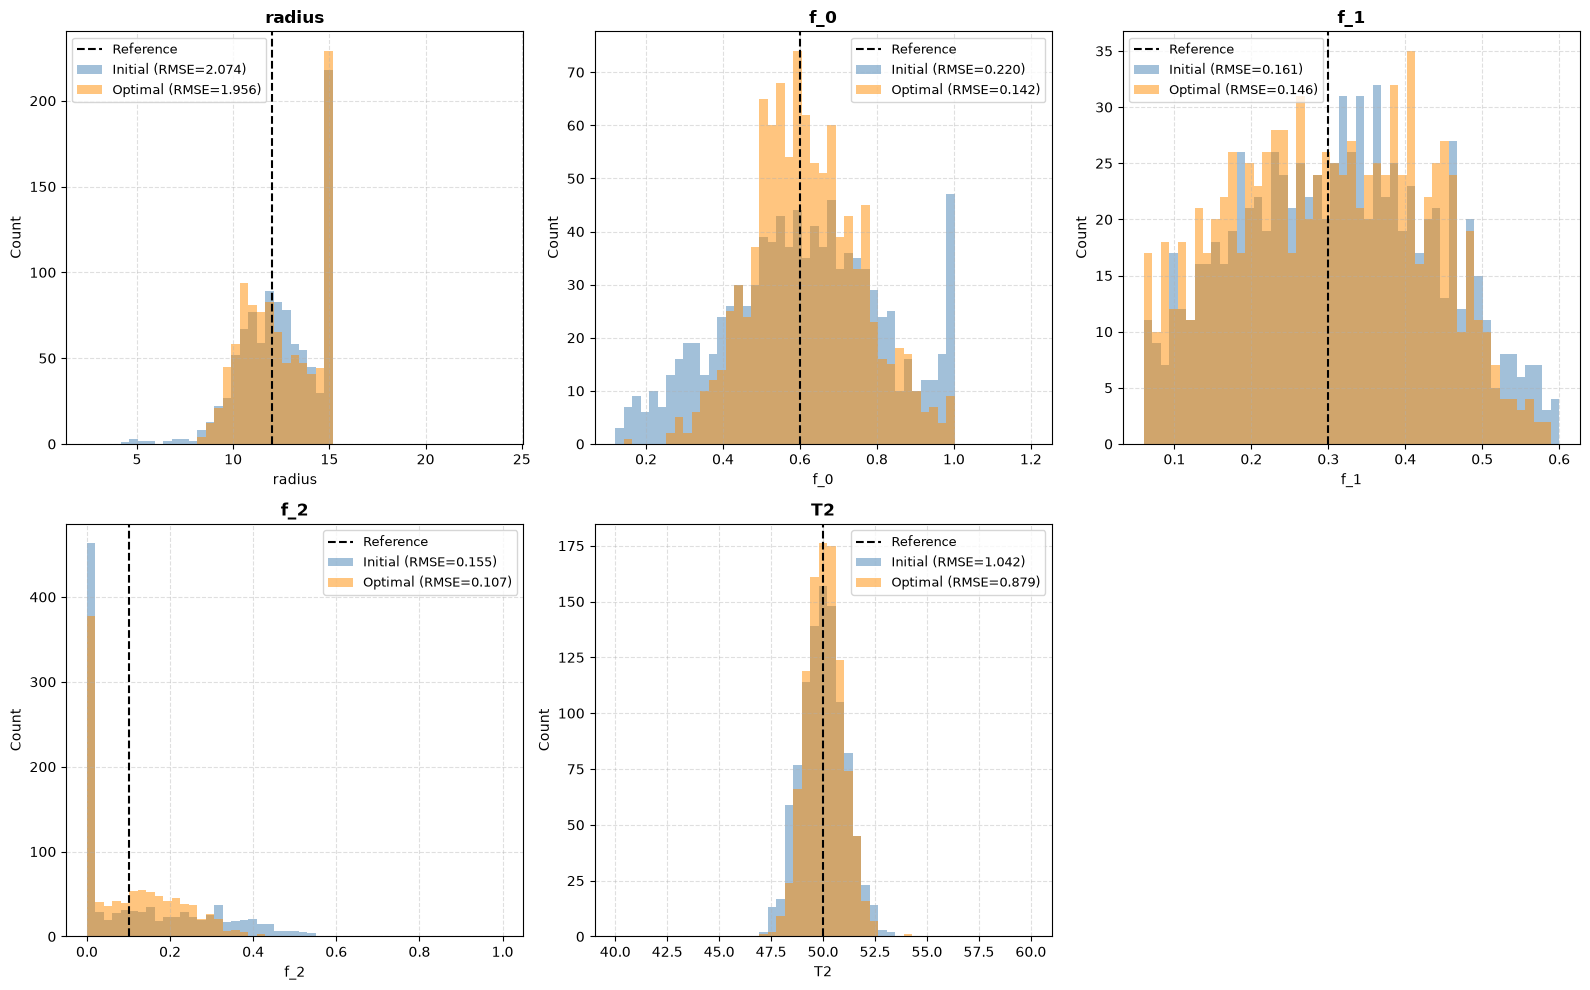

In [54]:
import numpy as np
from matplotlib import pyplot as plt

initial_result = initial
optimal_result = optimal

# Derived fraction f_2 = 1 - f_0 - f_1
initial_f2 = 1 - initial_result["model_f_0"] - initial_result["model_f_1"]
optimal_f2 = 1 - optimal_result["model_f_0"] - optimal_result["model_f_1"]
reference_f2 = 1 - model["model_f_0"].value - model["model_f_1"].value

# Reference values
radius_ref = model["model_radius"].value
f0_ref = model["model_f_0"].value
f1_ref = model["model_f_1"].value

# Identify T2 parameter name dynamically (e.g., model_t2 or model_T2)
t2_key = next((k for k in ["model_t2", "model_T2", "t2", "T2"] if k in initial_result), None)
if t2_key is None:
    raise KeyError("Could not find T2 parameter in simulation results. Check result keys.")
t2_ref = (model[t2_key].value)*1e3

# Define data mapping: (title, reference_val, initial_vals, optimal_vals, bins)
plots_data = [
    (
        "radius",
        radius_ref,
        initial_result["model_radius"],
        optimal_result["model_radius"],
        np.linspace(0.2 * radius_ref, 2 * radius_ref, 50),
    ),
    (
        "f_0",
        f0_ref,
        initial_result["model_f_0"],
        optimal_result["model_f_0"],
        np.linspace(0.2 * f0_ref, 2 * f0_ref, 50),
    ),
    (
        "f_1",
        f1_ref,
        initial_result["model_f_1"],
        optimal_result["model_f_1"],
        np.linspace(0.2 * f1_ref, 2 * f1_ref, 50),
    ),
    (
        "f_2",
        reference_f2,
        initial_f2,
        optimal_f2,
        np.linspace(0, 1, 50),
    ),
    (
        "T2",
        t2_ref,
        initial_result[t2_key]*1e3,
        optimal_result[t2_key]*1e3,
        np.linspace(0.8 * t2_ref, 1.2 * t2_ref, 50),
    ),
]

# Create 2x3 subplot grid to accommodate 5 parameters
n_plots = len(plots_data)
ncols = 3
nrows = (n_plots + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows))
axes = axes.ravel()

for i, (name, ref, init_vals, opt_vals, bins) in enumerate(plots_data):
    ax = axes[i]
    init_rmse = np.sqrt(np.mean((init_vals - ref) ** 2))
    opt_rmse = np.sqrt(np.mean((opt_vals - ref) ** 2))

    ax.axvline(ref, color="black", linestyle="--", linewidth=1.5, label="Reference")
    ax.hist(
        init_vals,
        bins=bins,
        alpha=0.5,
        color="steelblue",
        label=f"Initial (RMSE={init_rmse:.3f})",
    )
    ax.hist(
        opt_vals,
        bins=bins,
        alpha=0.5,
        color="darkorange",
        label=f"Optimal (RMSE={opt_rmse:.3f})",
    )

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel(name)
    ax.set_ylabel("Count")
    ax.legend(fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.4)

# Hide any unused subplots in the grid
for j in range(len(plots_data), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()